# 3. Machine Learning

**Goal:** predict each player's MVP vote share, then rank players to find the MVP.

- **Model:** LightGBM regressor
- **Train:** seasons 1991–2024
- **Test:** season 2025 (never seen during training or tuning)

### How this model was chosen

Models were compared with a **season-by-season backtest (2010–2024)**: for each season, train on all earlier seasons and predict that season.
Metric: average precision (AP) of the predicted ranking against the real top 5.

| Model | Mean AP | MVP correct (of 15) |
|---|---|---|
| Baseline: sort by points | 0.690 | 5 |
| Baseline: points × team win % | 0.747 | 8 |
| Ridge regression | 0.758 | 7 |
| LightGBM, default parameters | 0.761 | 11 |
| **LightGBM, Optuna-tuned + era-normalized features** | **0.817** | 8 |

The tuned LightGBM had the best ranking quality, so it is the model used below. Its parameters were found with Optuna (30 trials), using the same backtest.

## 1. Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix, ConfusionMatrixDisplay

## 2. Load data

In [2]:
stats = pd.read_csv("player_mvp_stats.csv")

# The only missing values are shooting % for players with 0 attempts (0 / 0), so 0 is correct
stats = stats.fillna(0)
stats.shape

(16377, 40)

## 3. Features

Raw stats aren't comparable across eras (25 points per game means more in a low-scoring season).
So each key stat is also divided by that season's league average: `PTS_R = 2.0` means twice the league average that season.

Columns that are text, or that contain the answer (`Share`, `Pts Won`, `Pts Max`), are never used as features.

In [3]:
for col in ["PTS", "AST", "TRB", "STL", "BLK", "W/L%", "MP", "FG%"]:
    stats[f"{col}_R"] = stats[col] / stats.groupby("Year")[col].transform("mean")

target = "Share"   # MVP vote share, 0 to 1
not_features = ["Player", "Team", "Pos", "Year", "Pts Won", "Pts Max", "Share"]
predictors = [c for c in stats.columns if c not in not_features]

print(len(predictors), "features")

41 features


## 4. Train / test split

Split **by season**, not randomly. A random split would let the model learn from future seasons and would break up each season's MVP race.

In [4]:
train = stats[stats["Year"] <= 2024]
test = stats[stats["Year"] == 2025].copy()

print("Train:", train.shape, " seasons 1991-2024")
print("Test: ", test.shape, " season 2025")

Train: (15808, 48)  seasons 1991-2024
Test:  (569, 48)  season 2025


## 5. Train the model

In [5]:
best_params = {
    "n_estimators": 947,
    "learning_rate": 0.0153,
    "num_leaves": 31,
    "min_child_samples": 44,
    "subsample": 0.624,
    "subsample_freq": 1,
    "colsample_bytree": 0.763,
}

model = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1)

loss_history = {}
model.fit(
    train[predictors], train[target],
    eval_set=[(train[predictors], train[target]), (test[predictors], test[target])],
    eval_names=["train", "test"],
    eval_metric="l2",                                  # l2 = mean squared error
    callbacks=[lgb.record_evaluation(loss_history)],   # save the loss after every tree
)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.0153
,n_estimators,947
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,44


## 6. Loss curve

Loss = **mean squared error (MSE)** between predicted and actual vote share, measured after each tree.
Both curves go down and flatten: the model learned without overfitting.
(The test curve is only plotted; it was not used to choose anything.)

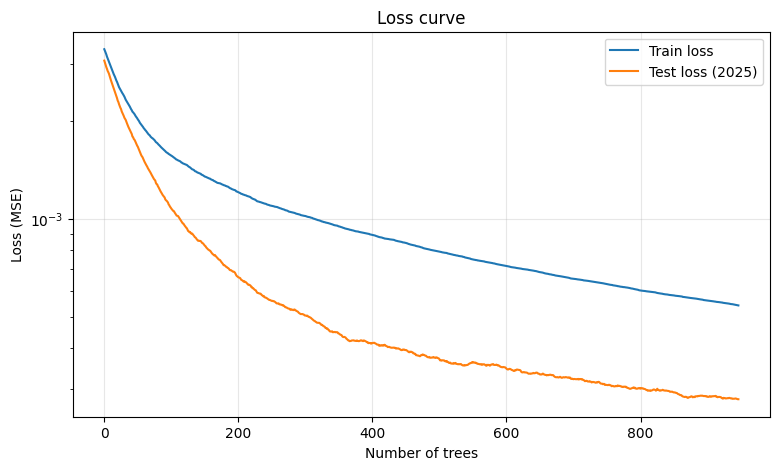

Final train loss (MSE): 0.000542
Final test loss  (MSE): 0.000279


In [6]:
plt.figure(figsize=(9, 5))
plt.plot(loss_history["train"]["l2"], label="Train loss")
plt.plot(loss_history["test"]["l2"], label="Test loss (2025)")
plt.xlabel("Number of trees")
plt.ylabel("Loss (MSE)")
plt.title("Loss curve")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Final train loss (MSE): {loss_history['train']['l2'][-1]:.6f}")
print(f"Final test loss  (MSE): {loss_history['test']['l2'][-1]:.6f}")

## 7. Predict 2025

In [7]:
test["Predicted"] = model.predict(test[predictors])
test["Predicted rank"] = test["Predicted"].rank(ascending=False, method="first").astype(int)
test["Actual rank"] = test["Share"].rank(ascending=False, method="first").astype(int)

## 8. Results: actual vs predicted

In [8]:
(test.sort_values("Predicted", ascending=False)
     [["Player", "Team", "Predicted", "Share", "Predicted rank", "Actual rank"]]
     .rename(columns={"Share": "Actual"})
     .head(10)
     .round(3)
     .reset_index(drop=True))

,Player,Team,Predicted,Actual,Predicted rank,Actual rank
0,Shai Gilgeous-Alexander,Oklahoma City Thunder,0.761,0.913,1,1
1,Nikola Jokić,Denver Nuggets,0.615,0.787,2,2
2,Giannis Antetokounmpo,Milwaukee Bucks,0.360,0.470,3,3
3,Jayson Tatum,Boston Celtics,0.173,0.311,4,4
4,Donovan Mitchell,Cleveland Cavaliers,0.088,0.074,5,5
5,Trae Young,Atlanta Hawks,0.087,0.000,6,26
6,Jalen Williams,Oklahoma City Thunder,0.085,0.000,7,38
7,Darius Garland,Cleveland Cavaliers,0.056,0.000,8,46
8,James Harden,Los Angeles Clippers,0.055,0.001,9,11
9,Victor Wembanyama,San Antonio Spurs,0.054,0.000,10,24


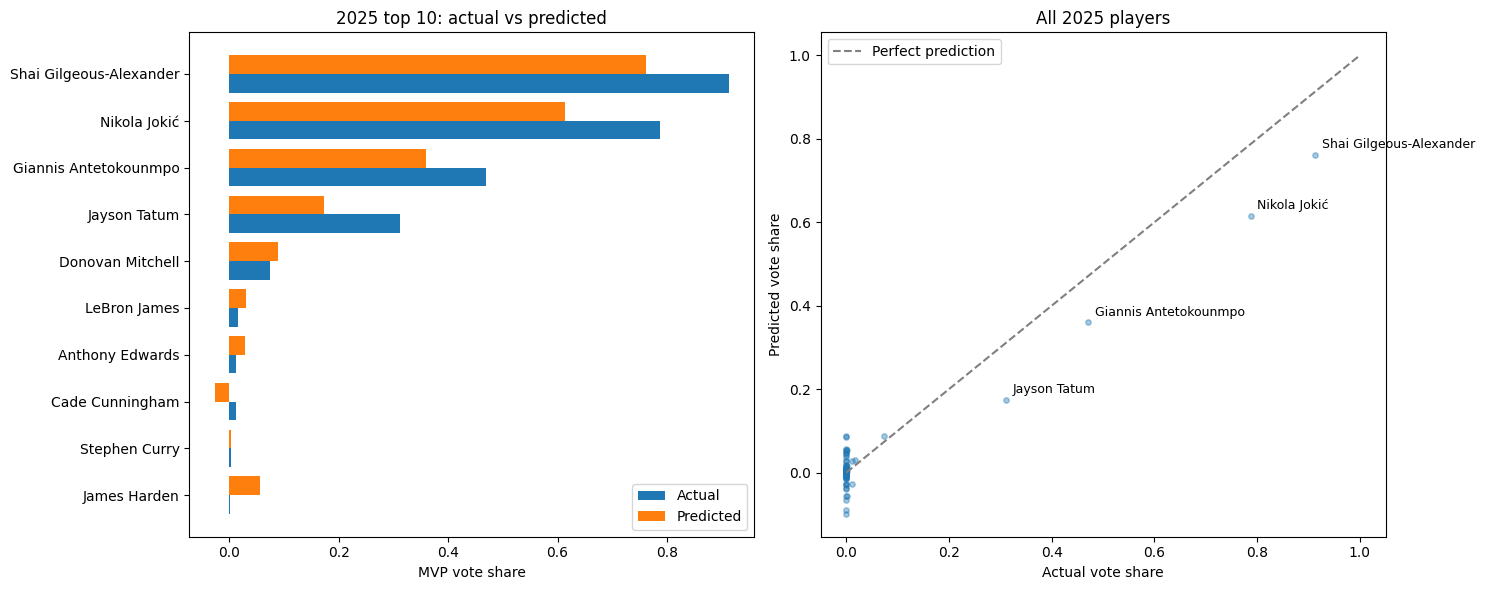

In [9]:
top = test.sort_values("Share", ascending=False).head(10).iloc[::-1]
y = np.arange(len(top))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(y - 0.2, top["Share"], height=0.4, label="Actual")
axes[0].barh(y + 0.2, top["Predicted"], height=0.4, label="Predicted")
axes[0].set_yticks(y)
axes[0].set_yticklabels(top["Player"])
axes[0].set_xlabel("MVP vote share")
axes[0].set_title("2025 top 10: actual vs predicted")
axes[0].legend()

axes[1].scatter(test["Share"], test["Predicted"], alpha=0.4, s=15)
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Perfect prediction")
for _, row in test.sort_values("Share", ascending=False).head(4).iterrows():
    axes[1].annotate(row["Player"], (row["Share"], row["Predicted"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
axes[1].set_xlabel("Actual vote share")
axes[1].set_ylabel("Predicted vote share")
axes[1].set_title("All 2025 players")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Scores

- **MSE / RMSE / MAE:** how far predicted vote shares are from the real ones (lower is better)
- **R²:** share of the variation the model explains (1.0 = perfect)
- **MVP correct:** did the model's #1 pick win?
- **Top-5 accuracy:** how many of the real top 5 are in the predicted top 5

In [10]:
mse = mean_squared_error(test["Share"], test["Predicted"])

predicted_mvp = test.loc[test["Predicted rank"] == 1, "Player"].iloc[0]
actual_mvp = test.loc[test["Actual rank"] == 1, "Player"].iloc[0]
top5_hits = len(set(test.loc[test["Predicted rank"] <= 5, "Player"]) &
                set(test.loc[test["Actual rank"] <= 5, "Player"]))

pd.Series({
    "MSE (loss)": round(mse, 5),
    "RMSE": round(np.sqrt(mse), 4),
    "MAE": round(mean_absolute_error(test["Share"], test["Predicted"]), 4),
    "R²": round(r2_score(test["Share"], test["Predicted"]), 3),
    "Predicted MVP": predicted_mvp,
    "Actual MVP": actual_mvp,
    "MVP correct": predicted_mvp == actual_mvp,
    "Top-5 accuracy": f"{top5_hits}/5 ({top5_hits / 5:.0%})",
}, name="2025 test").to_frame()

,2025 test
MSE (loss),0.00028
RMSE,0.0167
MAE,0.0039
R²,0.91
Predicted MVP,Shai Gilgeous-Alexander
Actual MVP,Shai Gilgeous-Alexander
MVP correct,True
Top-5 accuracy,5/5 (100%)


## 10. Confusion matrix: top-5 contenders

Each player is labeled **Top 5** or **Not top 5**, once by the real votes and once by the model.

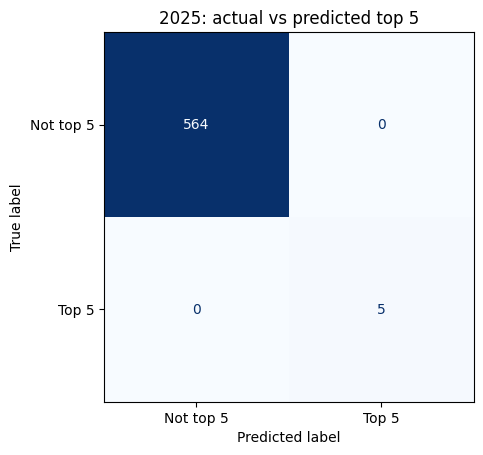

In [11]:
cm = confusion_matrix(test["Actual rank"] <= 5, test["Predicted rank"] <= 5)
ConfusionMatrixDisplay(cm, display_labels=["Not top 5", "Top 5"]).plot(cmap="Blues", colorbar=False)
plt.title("2025: actual vs predicted top 5")
plt.show()

## 11. Save the final model

Testing is done, so the final model is retrained on **all** seasons (1991–2025) with the same parameters,
then saved together with its feature list. `04_test_2026_season.ipynb` loads this file to predict a new season.

In [12]:
final_model = lgb.LGBMRegressor(**best_params, random_state=42, verbose=-1)
final_model.fit(stats[predictors], stats[target])

joblib.dump({"model": final_model, "predictors": predictors}, "mvp_model.joblib")
print("Saved mvp_model.joblib with", len(predictors), "features")

Saved mvp_model.joblib with 41 features


## Summary

- **2025 test:** MVP correct (Shai Gilgeous-Alexander), and the predicted top 5 matches the real top 5 in the same order.
- **Backtest 2010–2024:** MVP correct in 8 of 15 seasons, mean AP 0.82. One perfect season is partly luck, so the backtest is the realistic expectation.
- **Typical misses:** players whose MVP case rests on advanced or defensive impact (Nikola Jokić 2021–22) or narrative (Derrick Rose 2011, Russell Westbrook 2017).